# Branch from 2 outputs - Adjacency matrices for every case, as handed to the quantum codes

`2_graph_generation.ipynb` produces one weighted adjacency matrix per subgraph. This notebook
collects the matrices for **all** the cases reported in the study in one place, so the input to
the quantum stage is a single, inspectable artefact rather than something regenerated per run. Stages 1-3 follow one organism end to end (the 24-node African swine fever virus graph). This notebook is the other axis: the same Stage 2 procedure applied to nine different subgraphs,
spanning 4 to 31 nodes and six organisms.

**Input.** The graphs Stage 2 emitted for each case, recorded below as `node_ids` + weighted
`edges`. Edge weights are suffix/prefix overlap scores - a local alignment, match +1 / mismatch -1
/ gap open -1 / gap extend -1, over a 100-base terminal window.

**Output.** One CSV per case, `adjacency/<case>.csv`, holding the weighted adjacency matrix
`W[i, j]` = overlap score of edge `i -> j`, zero where no edge exists. This is what the
HUBO/CVaR-VQE stage consumes; the solved node order it returns goes to
`3_contig_generation.ipynb`.

**Pipeline position.** reads -> duplicate removal (Stage 1) -> overlap scoring -> subgraph +
Hamiltonian verification (Stage 2, repeated per case) -> **this notebook** -> quantum solver ->
contig generation (Stage 3).

In [2]:
# Setup: imports and the same graph drawing helper used in Stages 2 and 3.
import json
import os

import networkx as nx
import matplotlib.pyplot as plt
import numpy as np


def show_wgraph(G):
    """Draw a weighted directed graph with its edge weights labelled."""
    plt.figure()
    pos = nx.spring_layout(G)
    weight_labels = nx.get_edge_attributes(G, 'weight')
    nx.draw(G, pos, font_color='white', font_size=6, node_shape='s',
            node_size=70, with_labels=True)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=weight_labels, font_size=6)

7
node_count: 4  edge_count: 7
[[ 0. 19.  0.  0.]
 [18.  0. 19.  0.]
 [ 0. 19.  0. 18.]
 [18. 18.  0.  0.]]


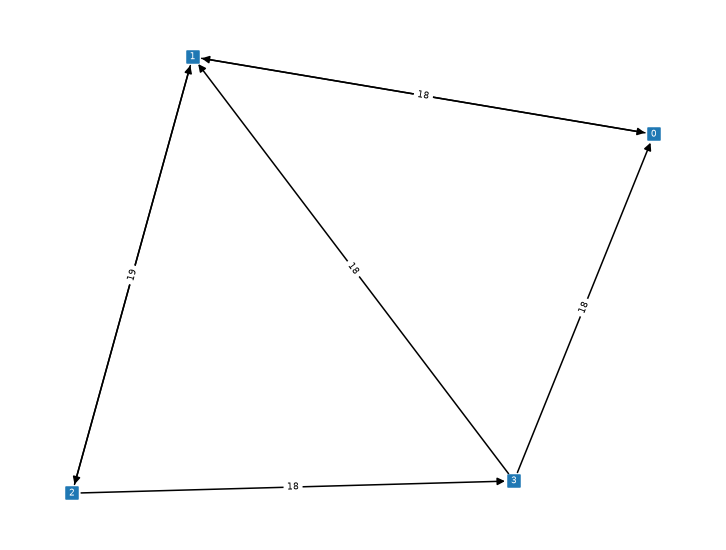

In [3]:
#example olc graph - case 1 (Bacillus Cereus - bacteria)

node=[238,393,133,464]
node_num=list(range(0,4))
edge_list=[[0,1,19],[1,2,19],[2,3,18],[3,0,18],[3,1,18],[2,1,19],[1,0,18]]
matrix = np.zeros((len(node_num),len(node_num)))


edge_list
print(len(edge_list))
G = nx.DiGraph()
G.add_nodes_from(node_num)
G.add_weighted_edges_from(edge_list)
print("node_count:",G.number_of_nodes()," edge_count:",G.number_of_edges())
G.number_of_edges()
show_wgraph(G)

case1=nx.to_numpy_array(G, nodelist=node_num)
print(case1)

### Stage 2 output — Bacillus cereus (SRR12045421), 4 nodes

Hamiltonian path found classically in Stage 2, in **positional** node order (indices into `node_num`, i.e. the same order as the rows and columns of the adjacency matrix printed above):

`0 -> 1 -> 2 -> 3`

Total overlap weight **56**. This is the reference the quantum solution is scored against: a consecutive pair that is not an edge of this graph counts as a violation.

Backmapped to the original read ids `[238, 393, 133, 464]`, this is the highest-scoring of the 5 Hamiltonian paths this graph admits; the next three score 55, 55 and 54.

> **Corrected.** The earlier version of this cell listed the paths as `3 -> 0 -> 2 -> 1`, `2 -> 0 -> 3 -> 1`, `3 -> 1 -> 0 -> 2`, `2 -> 1 -> 0 -> 3`. None of those is a path in this edge list — edge `0 -> 2` does not exist. Re-enumerating over the stored edges gives 5 paths, the best being the one above at weight 56, which is the weight the old notes already recorded for `[238, 393, 133, 464]`. Note the maximum is tied: `3 -> 0 -> 1 -> 2` also scores 56.


17
node_count: 11  edge_count: 17
[[0. 5. 3. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 5. 4. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 6. 4. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 5. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 3. 0. 3. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 6. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 6. 4. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 5. 3.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 5.]
 [0. 0. 0. 0. 0. 3. 0. 3. 0. 0. 0.]]


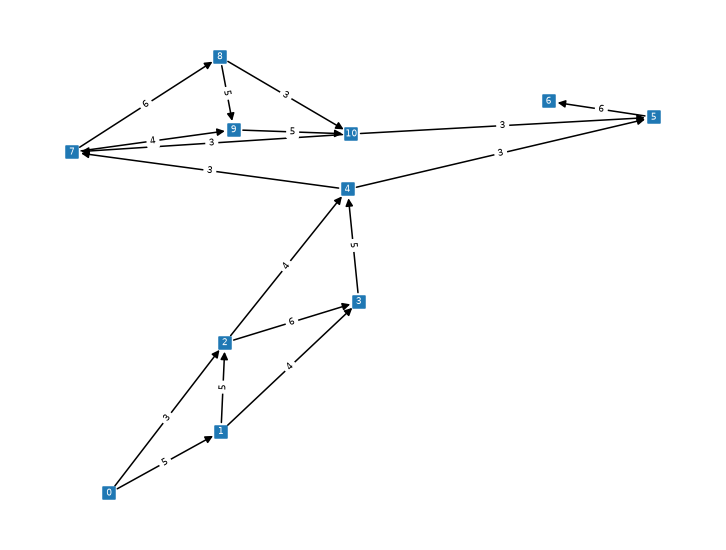

In [5]:
#example olc graph - case2 (a chunk of genome of some organism "GCATTATATATTGCGCGTACGGCGCCGCTACA" - test case )

node=['GCATTAT','ATTATAT','TATATTG','ATATTGC','ATTGCGC','CGCCGCT','GCCGCTA','CGCGTAC','GCGTACG','GTACGGC','ACGGCGC']
node_num=list(range(0,11))
edge_list=[[0,1,5],[0,2,3],[1,2,5],[2,3,6],[1,3,4],[2,4,4],[3,4,5],[4,5,3],[5,6,6],[4,7,3],[7,8,6],[8,9,5],[7,9,4],[9,10,5],[8,10,3],[10,5,3],[10,7,3]]

matrix = np.zeros((len(node_num),len(node_num)))


edge_list
print(len(edge_list))
G = nx.DiGraph()
G.add_nodes_from(node_num)
G.add_weighted_edges_from(edge_list)
print("node_count:",G.number_of_nodes()," edge_count:",G.number_of_edges())
G.number_of_edges()
show_wgraph(G)
case2=nx.to_numpy_array(G, nodelist=node_num)
print(case2)

### Stage 2 output — synthetic test case, 11 nodes

Original string: `GCATTATATATTGCGCGTACGGCGCCGCTACA`. This case is a hand-built string used to validate the graph construction, not a sequencing dataset, so it has no SRA accession.

Hamiltonian path in positional node order:

`0 -> 1 -> 2 -> 3 -> 4 -> 7 -> 8 -> 9 -> 10 -> 5 -> 6`

Total overlap weight **49**. The path is unique.


17
node_count: 7  edge_count: 17
[[ 0. 63. 67. 65. 67. 64.  0.]
 [ 0.  0. 60. 61. 60. 62.  0.]
 [ 0.  0.  0. 62. 65. 65. 61.]
 [ 0.  0.  0.  0. 65. 60.  0.]
 [ 0.  0.  0.  0.  0. 61.  0.]
 [ 0.  0.  0.  0.  0.  0. 63.]
 [ 0.  0.  0.  0.  0.  0.  0.]]


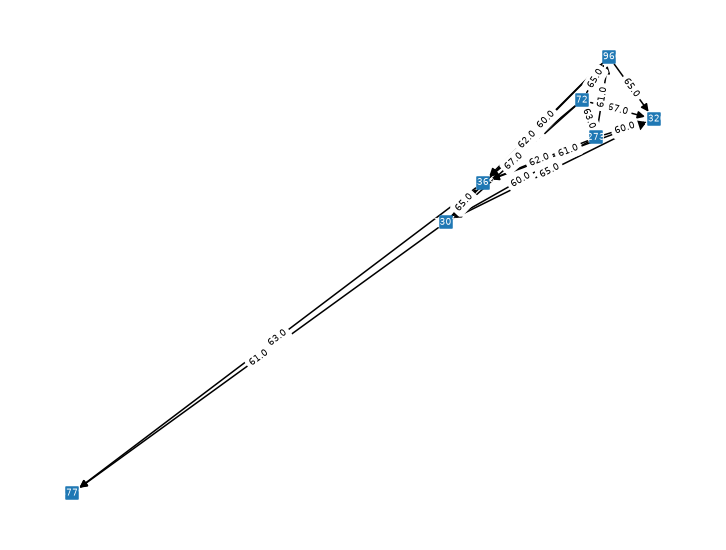

In [7]:
#example olc graph - case 3 (Bacteriodes Intenstinalis - bacteria)

node_num = [72, 273, 1307, 3966, 4320, 4369, 4779]
edge_list=[[72, 273, 63.0], [72, 1307, 67.0], [72, 3966, 65.0], [72, 4320, 67.0], [72, 4369, 64.0], [273, 1307, 60.0], [273, 3966, 61.0], [273, 4320, 60.0], [273, 4369, 62.0], [1307, 3966, 62.0], [1307, 4320, 65.0], [1307, 4369, 65.0], [1307, 4779, 61.0], [3966, 4320, 65.0], [3966, 4369, 60.0], [4320, 4369, 61.0], [4369, 4779, 63.0]]

matrix = np.zeros((len(node_num),len(node_num)))

print(len(edge_list))
G = nx.DiGraph()
G.add_nodes_from(node_num)
G.add_weighted_edges_from(edge_list)
print("node_count:",G.number_of_nodes()," edge_count:",G.number_of_edges())
G.number_of_edges()
show_wgraph(G)
case3=nx.to_numpy_array(G, nodelist=node_num)
print(case3)

### Stage 2 output — Bacteroides intestinalis (SRR13062400), 7 nodes

Hamiltonian path found classically in Stage 2, in **positional** node order (indices into `node_num`, i.e. the same order as the rows and columns of the adjacency matrix printed above):

`0 -> 1 -> 2 -> 3 -> 4 -> 5 -> 6`

Total overlap weight **374**. This is the reference the quantum solution is scored against: a consecutive pair that is not an edge of this graph counts as a violation.

Backmapped to the original read ids: `72 -> 273 -> 1307 -> 3966 -> 4320 -> 4369 -> 4779`. The path is unique.

> No path was written down for this case in the earlier notebook; the one above was recomputed from the stored edge list by exhaustive enumeration.


node_count: 18  edge_count: 29
[[ 0. 24.  0.  0.  0.  0. 21.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0. 22. 25. 21.  0.  0.  0.  0. 22.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0. 24.  0.  0.  0. 21.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0. 22.  0.  0.  0.  0.  0. 23.  0.  0.  0.  0.  0. 21.  0.]
 [ 0.  0.  0.  0.  0. 21.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0. 21.  0.  0.  0. 25.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0. 21.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0. 21.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0. 25. 25.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0. 26.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. 21.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. 21.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. 21. 21.  0.  0.

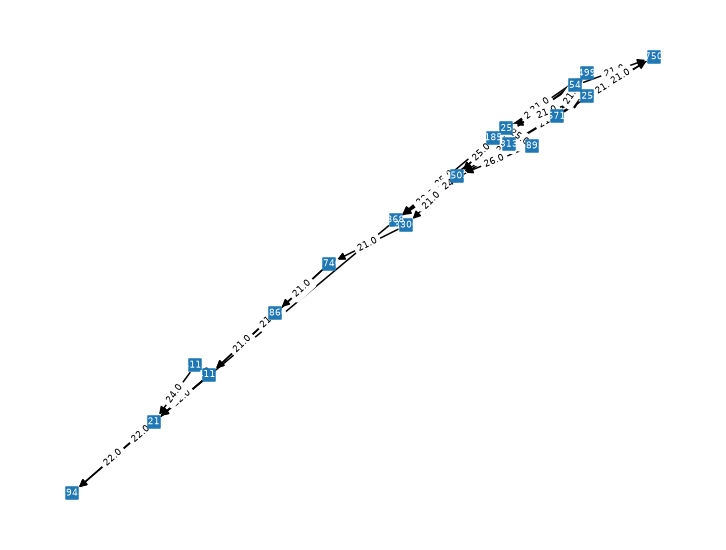

In [9]:
#example olc graph - case 4 (avian influenza (HPAI) H5N1 virus detected in Brown Skua (SRR32006043) - virus)
#18 node graph

node_num = [54, 185, 313, 368, 499, 571, 750, 1250, 1257, 1893, 2503, 3300, 3740, 3860, 4113, 4117, 4217, 4943]
edge_list=[[54, 185, 24.0], [54, 750, 21.0], [185, 313, 22.0], [185, 368, 25.0], [185, 499, 21.0], [185, 1893, 22.0], [750, 1250, 21.0], [313, 368, 24.0], [313, 1250, 21.0], [368, 499, 22.0], [368, 2503, 23.0], [368, 4217, 21.0], [499, 571, 21.0], [1893, 2503, 26.0], [1250, 1257, 21.0], [2503, 3300, 21.0], [4217, 4943, 22.0], [571, 750, 21.0], [571, 2503, 25.0], [1257, 1893, 25.0], [1257, 2503, 25.0], [3300, 3740, 21.0], [3740, 3860, 21.0], [3740, 4113, 21.0], [3860, 4113, 21.0], [4113, 4117, 22.0], [4113, 4217, 22.0], [4113, 4943, 22.0], [4117, 4217, 24.0]]

matrix = np.zeros((len(node_num),len(node_num)))

#print(len(edge_list))
G = nx.DiGraph()
G.add_nodes_from(node_num)
G.add_weighted_edges_from(edge_list)
print("node_count:",G.number_of_nodes()," edge_count:",G.number_of_edges())
G.number_of_edges()
show_wgraph(G)
case4=nx.to_numpy_array(G, nodelist=node_num)
print(case4)

### Stage 2 output — Avian influenza (HPAI) H5N1, Brown Skua (SRR32006043), 18 nodes

Hamiltonian path found classically in Stage 2, in **positional** node order (indices into `node_num`, i.e. the same order as the rows and columns of the adjacency matrix printed above):

`0 -> 1 -> 2 -> 3 -> 4 -> 5 -> 6 -> 7 -> 8 -> 9 -> 10 -> 11 -> 12 -> 13 -> 14 -> 15 -> 16 -> 17`

Total overlap weight **379**. This is the reference the quantum solution is scored against: a consecutive pair that is not an edge of this graph counts as a violation.

In positional order the path runs straight through `node_num`, so backmapped it is simply that list in order: `54 -> 185 -> 313 -> 368 -> ... -> 4943`. The path is unique.

> No path was written down for this case in the earlier notebook; the one above was recomputed from the stored edge list by exhaustive enumeration.


node_count: 6  edge_count: 19
[[ 0. 23. 18. 18. 24.  0.]
 [ 0.  0. 22. 16. 24. 22.]
 [ 0.  0. 20. 18. 20. 22.]
 [ 0.  0.  0. 20. 25.  0.]
 [ 0.  0.  0. 16. 22.  0.]
 [ 0.  0. 17. 24. 21.  0.]]


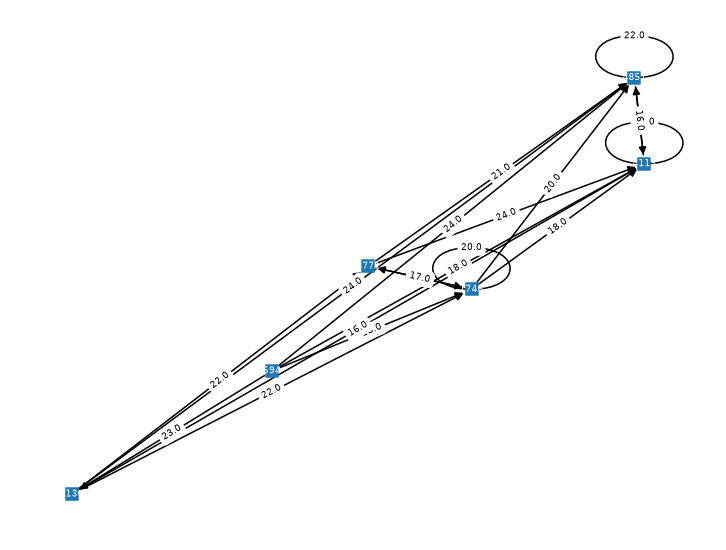

In [11]:
#example olc graph - case 5 (denv 2 (SRR32137766) - virus)
#6 node graph

node_num=[594, 1130, 1746, 4113, 4851, 3771]
edge_list=[[594, 1130, 23.0], [594, 1746, 18.0], [594, 4113, 18.0], [594, 4851, 24.0], [1130, 1746, 22.0], [1130, 3771, 22.0], [1130, 4113, 16.0], [1130, 4851, 24.0], [1746, 1746, 20.0], [1746, 3771, 22.0], [1746, 4113, 18.0], [1746, 4851, 20.0], [4113, 4113, 20.0], [4113, 4851, 25.0], [4851, 4113, 16.0], [4851, 4851, 22.0], [3771, 1746, 17.0], [3771, 4113, 24.0], [3771, 4851, 21.0]]

matrix = np.zeros((len(node_num),len(node_num)))

#print(len(edge_list))
G = nx.DiGraph()
G.add_nodes_from(node_num)
G.add_weighted_edges_from(edge_list)
print("node_count:",G.number_of_nodes()," edge_count:",G.number_of_edges())
G.number_of_edges()
show_wgraph(G)
case5=nx.to_numpy_array(G, nodelist=node_num)
print(case5)

### Stage 2 output — Dengue virus type 2, Bangladesh/NRICh-DS028/2023 (SRR32137766), 6 nodes

This graph admits **4** Hamiltonian paths. In positional node order, with the backmapped read ids and total overlap weight:

| positional path | backmapped read ids | weight |
|---|---|---|
| `0 -> 1 -> 2 -> 5 -> 3 -> 4` | 594, 1130, 1746, 3771, 4113, 4851 | **116** |
| `0 -> 1 -> 5 -> 2 -> 3 -> 4` | 594, 1130, 3771, 1746, 4113, 4851 | 105 |
| `0 -> 1 -> 2 -> 5 -> 4 -> 3` | 594, 1130, 1746, 3771, 4851, 4113 | 104 |
| `0 -> 1 -> 5 -> 2 -> 4 -> 3` | 594, 1130, 3771, 1746, 4851, 4113 | 98 |

The first is the reference the quantum solution is scored against, being the highest-scoring. A consecutive pair that is not an edge of this graph counts as a violation.


node_count: 9  edge_count: 17
[[ 0. 44.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0. 26.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0. 44.  0.  0. 16.  0.  0.]
 [ 0.  0.  0.  0. 21.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0. 22. 15. 16.  0.]
 [ 0.  0.  0.  0. 16.  0. 21.  0.  0.]
 [ 0.  0.  0. 19.  0. 18. 20. 21.  0.]
 [ 0.  0.  0.  0. 15. 16.  0.  0. 34.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.]]


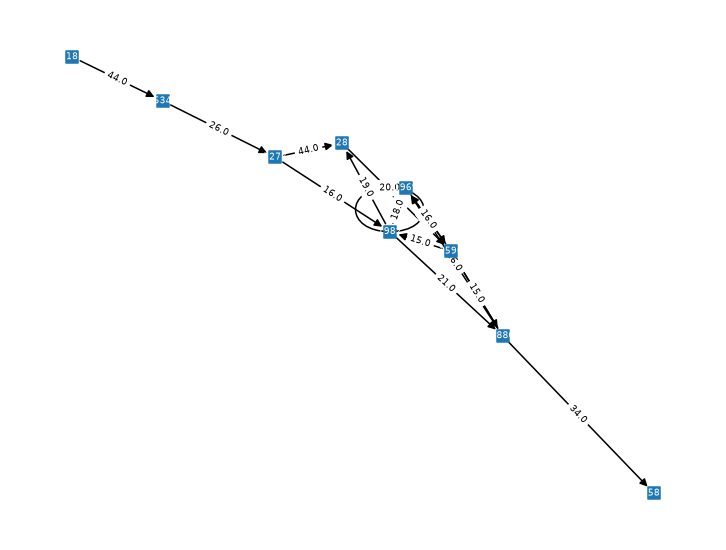

In [13]:
#example olc graph - case 6 (monkeypox (SRR32413059) - virus)
#9 node graph

node_num=[18, 534, 1277, 1281, 1596, 1969, 1982, 2880, 3581]
edge_list=[[18, 534, 44.0], [534, 1277, 26.0], [1277, 1281, 44.0], [1277, 1982, 16.0], [1281, 1596, 21.0], [1982, 1281, 19.0], [1982, 1969, 18.0], [1982, 1982, 20.0], [1982, 2880, 21.0], [1596, 1969, 22.0], [1596, 1982, 15.0], [1596, 2880, 16.0], [1969, 1596, 16.0], [1969, 1982, 21.0], [2880, 1596, 15.0], [2880, 1969, 16.0], [2880, 3581, 34.0]]

matrix = np.zeros((len(node_num),len(node_num)))

#print(len(edge_list))
G = nx.DiGraph()
G.add_nodes_from(node_num)
G.add_weighted_edges_from(edge_list)
print("node_count:",G.number_of_nodes()," edge_count:",G.number_of_edges())
G.number_of_edges()
show_wgraph(G)
case6=nx.to_numpy_array(G, nodelist=node_num)
print(case6)

### Stage 2 output — Monkeypox virus, Kenya isolate (SRR32413059), 9 nodes

Hamiltonian path found classically in Stage 2, in **positional** node order (indices into `node_num`, i.e. the same order as the rows and columns of the adjacency matrix printed above):

`0 -> 1 -> 2 -> 3 -> 4 -> 5 -> 6 -> 7 -> 8`

Total overlap weight **233**. This is the reference the quantum solution is scored against: a consecutive pair that is not an edge of this graph counts as a violation.

Backmapped to the original read ids: `18 -> 534 -> 1277 -> 1281 -> 1596 -> 1969 -> 1982 -> 2880 -> 3581`. The path is unique.


node_count: 21  edge_count: 160
[[ 0. 16. 12. 13. 14. 14. 16. 18. 14. 16. 14. 13. 14. 18. 15. 13. 15. 13.
   0.  0.  0.]
 [ 0.  0. 12. 13.  0. 12.  0. 16. 13. 17. 13.  0. 14.  0.  0. 21.  0.  0.
  16.  0. 14.]
 [ 0.  0.  0.  0.  0. 12.  0.  0.  0.  0. 17.  0.  0.  0.  0.  0.  0.  0.
  12.  0.  0.]
 [ 0.  0.  0.  0. 13. 13.  0. 17.  0. 14.  0.  0. 12. 14.  0. 17.  0.  0.
   0.  0. 12.]
 [ 0.  0. 12.  0.  0. 14.  0.  0. 14.  0.  0.  0.  0. 14. 14.  0.  0.  0.
   0.  0. 12.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0. 14.  0.  0.  0.  0.  0.  0.  0.
  12.  0.  0.]
 [ 0. 13.  0.  0.  0. 13.  0. 17. 12. 15. 14. 16. 15. 14. 13. 19. 13. 14.
   0.  0.  0.]
 [ 0.  0.  0.  0.  0. 18.  0.  0. 14. 16. 13.  0. 16. 13.  0. 18.  0.  0.
   0.  0. 13.]
 [ 0.  0.  0.  0.  0. 15.  0.  0.  0.  0. 13.  0.  0. 20. 13.  0.  0.  0.
  12.  0.  0.]
 [ 0.  0. 13.  0.  0. 18.  0.  0. 15.  0. 14.  0. 14. 17.  0. 19.  0.  0.
   0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
   0

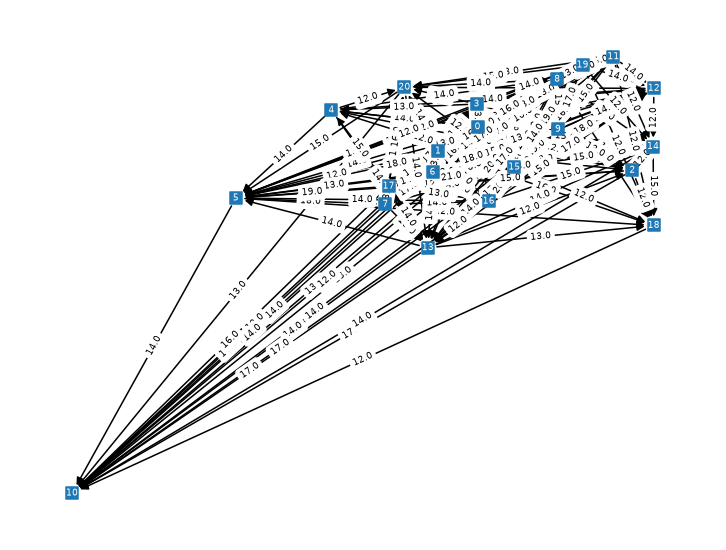

In [15]:
#example olc graph - case 7 (African swine fever virus, isolate NAM/P1/1995 (SRR27477754) - virus)
#21 node graph

node_num=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
edge_list= [[0, 1, 16.0], [0, 2, 12.0], [0, 3, 13.0], [0, 4, 14.0], [0, 5, 14.0], [0, 6, 16.0], [0, 7, 18.0], [0, 8, 14.0], [0, 9, 16.0], [0, 10, 14.0], [0, 11, 13.0], [0, 12, 14.0], [0, 13, 18.0], [0, 14, 15.0], [0, 15, 13.0], [0, 16, 15.0], [0, 17, 13.0], [1, 9, 17.0], [1, 12, 14.0], [1, 15, 21.0], [1, 3, 13.0], [1, 2, 12.0], [1, 20, 14.0], [1, 5, 12.0], [1, 7, 16.0], [1, 8, 13.0], [1, 18, 16.0], [1, 10, 13.0], [2, 5, 12.0], [2, 18, 12.0], [2, 10, 17.0], [3, 7, 17.0], [3, 9, 14.0], [3, 13, 14.0], [3, 12, 12.0], [3, 15, 17.0], [3, 4, 13.0], [3, 20, 12.0], [3, 5, 13.0], [4, 13, 14.0], [4, 14, 14.0], [4, 2, 12.0], [4, 5, 14.0], [4, 20, 12.0], [4, 8, 14.0], [5, 18, 12.0], [5, 10, 14.0], [6, 7, 17.0], [6, 10, 14.0], [6, 9, 15.0], [6, 12, 15.0], [6, 13, 14.0], [6, 16, 13.0], [6, 15, 19.0], [6, 14, 13.0], [6, 17, 14.0], [6, 8, 12.0], [6, 5, 13.0], [6, 11, 16.0], [6, 1, 13.0], [7, 8, 14.0], [7, 5, 18.0], [7, 9, 16.0], [7, 12, 16.0], [7, 10, 13.0], [7, 13, 13.0], [7, 15, 18.0], [7, 20, 13.0], [8, 14, 13.0], [8, 5, 15.0], [8, 18, 12.0], [8, 10, 13.0], [8, 13, 20.0], [9, 13, 17.0], [9, 10, 14.0], [9, 12, 14.0], [9, 2, 13.0], [9, 15, 19.0], [9, 5, 18.0], [9, 8, 15.0], [11, 17, 14.0], [11, 14, 12.0], [11, 15, 16.0], [11, 5, 12.0], [11, 1, 13.0], [11, 18, 12.0], [11, 10, 13.0], [11, 7, 17.0], [11, 9, 15.0], [11, 19, 15.0], [11, 20, 13.0], [11, 8, 13.0], [11, 13, 20.0], [11, 12, 14.0], [12, 13, 15.0], [12, 14, 12.0], [12, 15, 18.0], [12, 4, 14.0], [12, 20, 12.0], [12, 5, 13.0], [13, 5, 14.0], [13, 18, 13.0], [13, 10, 17.0], [13, 14, 14.0], [13, 2, 12.0], [14, 10, 14.0], [14, 2, 12.0], [14, 5, 13.0], [14, 18, 15.0], [15, 4, 12.0], [15, 20, 12.0], [15, 18, 12.0], [15, 8, 12.0], [15, 10, 14.0], [15, 13, 14.0], [15, 14, 15.0], [16, 1, 16.0], [16, 8, 12.0], [16, 5, 14.0], [16, 13, 12.0], [16, 14, 15.0], [16, 7, 14.0], [16, 10, 17.0], [16, 9, 15.0], [16, 17, 13.0], [16, 12, 17.0], [16, 15, 20.0], [17, 7, 18.0], [17, 9, 18.0], [17, 13, 14.0], [17, 10, 16.0], [17, 14, 13.0], [17, 12, 13.0], [17, 2, 15.0], [17, 15, 21.0], [17, 5, 19.0], [17, 4, 15.0], [17, 1, 19.0], [17, 20, 16.0], [17, 8, 16.0], [18, 10, 12.0], [19, 17, 14.0], [19, 15, 19.0], [19, 1, 16.0], [19, 14, 12.0], [19, 3, 14.0], [19, 5, 12.0], [19, 16, 14.0], [19, 18, 12.0], [19, 20, 15.0], [19, 7, 17.0], [19, 10, 12.0], [19, 9, 17.0], [19, 8, 13.0], [19, 12, 14.0], [19, 13, 17.0], [20, 8, 14.0], [20, 5, 15.0], [20, 13, 14.0], [20, 10, 13.0]]
matrix = np.zeros((len(node_num),len(node_num)))

#print(len(edge_list))
G = nx.DiGraph()
G.add_nodes_from(node_num)
G.add_weighted_edges_from(edge_list)
print("node_count:",G.number_of_nodes()," edge_count:",G.number_of_edges())
G.number_of_edges()
show_wgraph(G)
case7=nx.to_numpy_array(G, nodelist=node_num)
print(case7)

### Stage 2 output — African swine fever virus, isolate NAM/P1/1995 (SRR27477754), 21 nodes

Hamiltonian path found classically in Stage 2, in **positional** node order (indices into `node_num`, i.e. the same order as the rows and columns of the adjacency matrix printed above):

`0 -> 6 -> 11 -> 19 -> 16 -> 17 -> 1 -> 3 -> 7 -> 9 -> 12 -> 15 -> 4 -> 20 -> 8 -> 13 -> 14 -> 2 -> 5 -> 18 -> 10`

Total overlap weight **291**. This is the reference the quantum solution is scored against: a consecutive pair that is not an edge of this graph counts as a violation.

> **Accession corrected** in the cell above, from `SRR32006043` to `SRR27477754`. Supplementary Table S3 assigns African swine fever virus to SRR27477754; SRR32006043 is the avian influenza dataset used for the 18-node graph.


node_count: 24  edge_count: 276
[[ 0. 14. 16. 14. 11. 14. 15. 16. 13. 14. 11. 11. 18. 13. 10. 15. 14. 13.
  12. 16. 13. 10. 13. 18.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0. 14. 12.  0.  0.  0.  0.  0.  0.  0.
   0.  0.  0.  0.  0.  0.]
 [ 0. 13.  0. 10. 10. 12. 13. 15. 16. 14. 11. 11. 14. 19.  9. 13. 15. 10.
  10. 13. 19.  8. 14. 17.]
 [ 0. 14.  0.  0. 12. 14.  0.  0.  0. 11. 11.  0. 14. 15.  0. 14.  0.  0.
  12.  0.  0.  0.  0.  0.]
 [ 0. 15.  0.  0.  0. 14.  0.  0.  0. 13.  9.  0. 14. 14.  0. 11.  0.  0.
  10.  0.  0.  0.  0.  0.]
 [ 0. 15.  0.  0.  0.  0.  0.  0.  0. 13. 12.  0. 20. 18.  0. 13.  0.  0.
  11.  0.  0.  0.  0.  0.]
 [ 0. 14.  0. 11. 11. 12.  0. 15.  0. 17.  9.  0. 12. 19.  0. 15. 17. 10.
   9. 16. 20.  0. 13. 14.]
 [ 0. 18.  0. 10. 11. 15.  0.  0.  0. 14.  9.  0. 17. 14.  0. 10. 14.  0.
  13.  0. 19.  0.  0.  0.]
 [ 0. 12.  0. 11. 13. 13. 11. 15.  0. 13. 12. 12. 20. 17. 11. 12. 14. 11.
  11. 13. 16. 15. 14. 17.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  

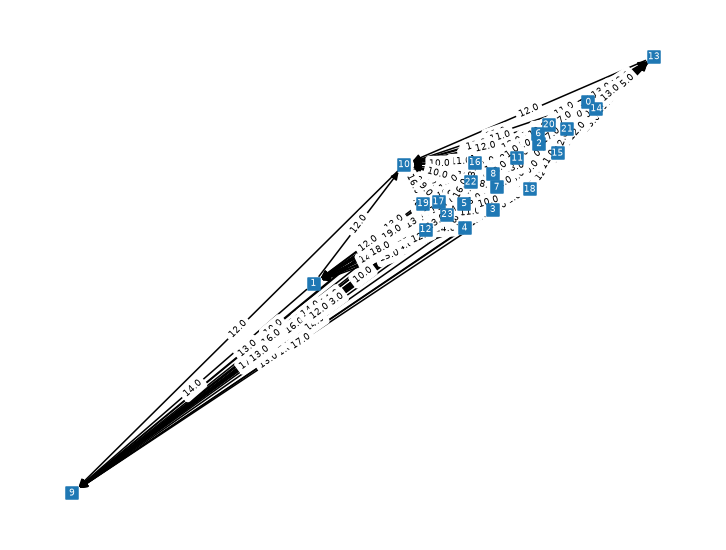

In [17]:
#example olc graph - case 8 (African swine fever virus, isolate NAM/P1/1995 (SRR27477754) - virus)
#24 node graph

node_num=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,21,22,23]
edge_list= [[0, 1, 14.0], [0, 5, 14.0], [0, 6, 15.0], [0, 7, 16.0], [0, 10, 11.0], [0, 12, 18.0], [0, 15, 15.0], [0, 16, 14.0], [0, 13, 13.0], [0, 9, 14.0], [0, 22, 13.0], [0, 2, 16.0], [0, 20, 13.0], [0, 18, 12.0], [0, 19, 16.0], [0, 8, 13.0], [0, 17, 13.0], [0, 11, 11.0], [0, 14, 10.0], [0, 21, 10.0], [0, 3, 14.0], [0, 23, 18.0], [0, 4, 11.0], [1, 10, 12.0], [1, 9, 14.0], [2, 3, 10.0], [2, 4, 10.0], [2, 5, 12.0], [2, 13, 19.0], [2, 17, 10.0], [2, 14, 9.0], [2, 18, 10.0], [2, 1, 13.0], [2, 23, 17.0], [2, 12, 14.0], [2, 21, 8.0], [2, 10, 11.0], [2, 7, 15.0], [2, 8, 16.0], [2, 16, 15.0], [2, 9, 14.0], [2, 15, 13.0], [2, 20, 19.0], [2, 6, 13.0], [2, 11, 11.0], [2, 22, 14.0], [2, 19, 13.0], [3, 13, 15.0], [3, 18, 12.0], [3, 4, 12.0], [3, 1, 14.0], [3, 5, 14.0], [3, 10, 11.0], [3, 12, 14.0], [3, 15, 14.0], [3, 9, 11.0], [4, 5, 14.0], [4, 12, 14.0], [4, 1, 15.0], [4, 15, 11.0], [4, 10, 9.0], [4, 13, 14.0], [4, 9, 13.0], [4, 18, 10.0], [5, 13, 18.0], [5, 18, 11.0], [5, 1, 15.0], [5, 10, 12.0], [5, 9, 13.0], [5, 12, 20.0], [5, 15, 13.0], [6, 3, 11.0], [6, 17, 10.0], [6, 4, 11.0], [6, 13, 19.0], [6, 22, 13.0], [6, 18, 9.0], [6, 23, 14.0], [6, 5, 12.0], [6, 19, 16.0], [6, 12, 12.0], [6, 15, 15.0], [6, 7, 15.0], [6, 1, 14.0], [6, 10, 9.0], [6, 16, 17.0], [6, 20, 20.0], [6, 9, 17.0], [7, 3, 10.0], [7, 4, 11.0], [7, 5, 15.0], [7, 13, 14.0], [7, 12, 17.0], [7, 18, 13.0], [7, 15, 10.0], [7, 16, 14.0], [7, 1, 18.0], [7, 10, 9.0], [7, 20, 19.0], [7, 9, 14.0], [8, 9, 13.0], [8, 11, 12.0], [8, 14, 11.0], [8, 15, 12.0], [8, 20, 16.0], [8, 21, 15.0], [8, 19, 13.0], [8, 3, 11.0], [8, 17, 11.0], [8, 6, 11.0], [8, 13, 17.0], [8, 22, 14.0], [8, 18, 11.0], [8, 23, 17.0], [8, 7, 15.0], [8, 1, 12.0], [8, 10, 12.0], [8, 4, 13.0], [8, 5, 13.0], [8, 12, 20.0], [8, 16, 14.0], [10, 9, 12.0], [11, 14, 14.0], [11, 19, 12.0], [11, 21, 13.0], [11, 17, 12.0], [11, 6, 12.0], [11, 20, 17.0], [11, 3, 11.0], [11, 4, 13.0], [11, 15, 12.0], [11, 22, 13.0], [11, 23, 16.0], [11, 5, 13.0], [11, 9, 16.0], [11, 13, 13.0], [11, 7, 19.0], [11, 16, 15.0], [11, 18, 11.0], [11, 12, 16.0], [11, 1, 13.0], [11, 10, 11.0], [12, 15, 14.0], [12, 13, 13.0], [12, 9, 17.0], [12, 18, 12.0], [12, 1, 14.0], [12, 10, 13.0], [13, 18, 13.0], [13, 1, 12.0], [13, 10, 12.0], [13, 9, 10.0], [14, 17, 11.0], [14, 3, 10.0], [14, 13, 15.0], [14, 21, 13.0], [14, 6, 15.0], [14, 18, 11.0], [14, 4, 11.0], [14, 23, 18.0], [14, 7, 15.0], [14, 5, 11.0], [14, 22, 14.0], [14, 16, 14.0], [14, 1, 12.0], [14, 20, 18.0], [14, 12, 15.0], [14, 10, 11.0], [14, 19, 14.0], [14, 9, 13.0], [14, 15, 12.0], [15, 9, 14.0], [15, 13, 19.0], [15, 18, 12.0], [15, 1, 13.0], [15, 10, 15.0], [16, 20, 18.0], [16, 15, 12.0], [16, 9, 10.0], [16, 3, 14.0], [16, 13, 11.0], [16, 4, 12.0], [16, 18, 9.0], [16, 5, 11.0], [16, 12, 15.0], [16, 1, 13.0], [16, 10, 10.0], [17, 3, 13.0], [17, 4, 12.0], [17, 5, 11.0], [17, 13, 14.0], [17, 12, 14.0], [17, 18, 8.0], [17, 23, 17.0], [17, 1, 13.0], [17, 10, 9.0], [17, 7, 14.0], [17, 15, 11.0], [17, 16, 12.0], [17, 20, 17.0], [17, 9, 11.0], [18, 1, 12.0], [18, 10, 12.0], [18, 9, 17.0], [19, 9, 13.0], [19, 20, 21.0], [19, 15, 11.0], [19, 13, 10.0], [19, 17, 13.0], [19, 3, 11.0], [19, 18, 12.0], [19, 23, 16.0], [19, 1, 12.0], [19, 7, 17.0], [19, 4, 14.0], [19, 16, 14.0], [19, 10, 16.0], [19, 5, 13.0], [19, 12, 11.0], [20, 15, 15.0], [20, 13, 13.0], [20, 3, 12.0], [20, 9, 14.0], [20, 18, 10.0], [20, 4, 12.0], [20, 1, 11.0], [20, 5, 12.0], [20, 10, 12.0], [20, 12, 14.0], [21, 7, 17.0], [21, 6, 14.0], [21, 5, 13.0], [21, 1, 12.0], [21, 12, 17.0], [21, 22, 14.0], [21, 16, 14.0], [21, 10, 12.0], [21, 19, 16.0], [21, 9, 12.0], [21, 20, 19.0], [21, 15, 12.0], [21, 17, 14.0], [21, 13, 13.0], [21, 23, 17.0], [21, 18, 11.0], [21, 3, 10.0], [21, 4, 15.0], [22, 20, 21.0], [22, 19, 19.0], [22, 15, 13.0], [22, 9, 16.0], [22, 17, 6.0], [22, 3, 15.0], [22, 13, 17.0], [22, 23, 18.0], [22, 18, 15.0], [22, 1, 19.0], [22, 7, 18.0], [22, 4, 16.0], [22, 16, 13.0], [22, 10, 10.0], [22, 5, 16.0], [22, 12, 14.0], [23, 7, 16.0], [23, 16, 16.0], [23, 5, 14.0], [23, 20, 18.0], [23, 12, 13.0], [23, 3, 11.0], [23, 4, 13.0], [23, 1, 18.0], [23, 10, 9.0], [23, 9, 13.0], [23, 15, 11.0], [23, 13, 17.0], [23, 18, 10.0]]
matrix = np.zeros((len(node_num),len(node_num)))

#print(len(edge_list))
G = nx.DiGraph()
G.add_nodes_from(node_num)
G.add_weighted_edges_from(edge_list)
print("node_count:",G.number_of_nodes()," edge_count:",G.number_of_edges())
G.number_of_edges()
show_wgraph(G)
case8=nx.to_numpy_array(G, nodelist=node_num)
print(case8)

### Stage 2 output — African swine fever virus, isolate NAM/P1/1995 (SRR27477754), 24 nodes

Hamiltonian path found classically in Stage 2, in **positional** node order (indices into `node_num`, i.e. the same order as the rows and columns of the adjacency matrix printed above):

`0 -> 2 -> 8 -> 11 -> 14 -> 21 -> 6 -> 22 -> 19 -> 17 -> 23 -> 7 -> 16 -> 20 -> 3 -> 4 -> 5 -> 12 -> 15 -> 13 -> 18 -> 1 -> 10 -> 9`

Total overlap weight **335**. This is the reference the quantum solution is scored against: a consecutive pair that is not an edge of this graph counts as a violation.

This is the worked example carried through Stages 1-3. The hardware run for this graph returned a path with 4 violations at total weight 269 (Table II).

> **Accession corrected** in the cell above, from `SRR32006043` to `SRR27477754`.


node_count: 31  edge_count: 281
[[ 0. 19. 20. 19. 19. 22. 21.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
   0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0. 19. 20.  0. 21.  0. 21.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
   0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0. 25.  0.  0.  0.  0. 24. 22. 23. 25. 25. 24. 25.  0.  0.  0.
   0.  0.  0.  0.  0.  0. 19. 20.  0.  0. 19.  0.  0.]
 [ 0.  0.  0.  0. 23. 24.  0.  0. 19. 19. 20. 19. 21. 20. 20.  0.  0.  0.
   0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0. 20.  0. 22. 19. 20. 19.  0. 19.  0.  0.  0.  0.  0.
   0. 23.  0.  0.  0.  0.  0.  0.  0. 22. 19.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0. 20. 20. 19. 22. 21. 22. 21. 21.  0.  0.  0.
   0. 19.  0.  0.  0.  0.  0. 19.  0. 21. 21.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0. 19. 19. 19. 20. 21. 20. 20. 21. 21.
  21. 20. 21. 28. 21. 21. 19. 21.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0. 19.  0.  0.  0.  0.  0.  0.  0.  0. 22.

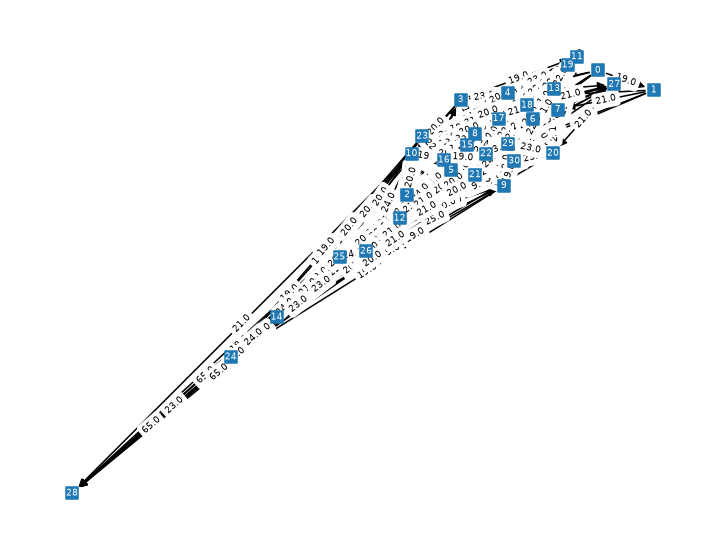

In [19]:
#example olc graph - case9 (hantavirus (SRR39057280) - virus)
#31 node graph

node_num= [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
edge_list= [[0, 1, 19.0], [0, 2, 20.0], [0, 3, 19.0], [0, 4, 19.0], [0, 5, 22.0], [0, 6, 21.0], [1, 2, 19.0], [1, 3, 20.0], [1, 5, 21.0], [1, 7, 21.0], [2, 8, 24.0], [2, 9, 22.0], [2, 10, 23.0], [2, 11, 25.0], [2, 12, 25.0], [2, 13, 24.0], [2, 14, 25.0], [2, 24, 19.0], [2, 25, 20.0], [2, 28, 19.0], [2, 3, 25.0], [3, 4, 23.0], [3, 5, 24.0], [3, 8, 19.0], [3, 9, 19.0], [3, 10, 20.0], [3, 11, 19.0], [3, 12, 21.0], [3, 13, 20.0], [3, 14, 20.0], [4, 5, 20.0], [4, 7, 22.0], [4, 27, 22.0], [4, 8, 19.0], [4, 19, 23.0], [4, 9, 20.0], [4, 10, 19.0], [4, 12, 19.0], [4, 28, 19.0], [5, 7, 20.0], [5, 27, 21.0], [5, 8, 20.0], [5, 19, 19.0], [5, 9, 19.0], [5, 10, 22.0], [5, 11, 21.0], [5, 12, 22.0], [5, 13, 21.0], [5, 14, 21.0], [5, 25, 19.0], [5, 28, 21.0], [6, 15, 20.0], [6, 16, 21.0], [6, 17, 21.0], [6, 18, 21.0], [6, 19, 20.0], [6, 20, 21.0], [6, 21, 28.0], [6, 22, 21.0], [6, 23, 21.0], [6, 9, 19.0], [6, 10, 19.0], [6, 11, 19.0], [6, 12, 20.0], [6, 13, 21.0], [6, 14, 20.0], [6, 24, 19.0], [6, 25, 21.0], [7, 6, 19.0], [7, 15, 22.0], [7, 26, 25.0], [7, 16, 24.0], [7, 17, 25.0], [7, 18, 25.0], [7, 29, 20.0], [7, 19, 21.0], [7, 20, 24.0], [7, 21, 25.0], [7, 22, 26.0], [7, 30, 22.0], [7, 23, 24.0], [7, 24, 21.0], [7, 25, 20.0], [8, 18, 22.0], [8, 29, 19.0], [8, 19, 22.0], [8, 20, 23.0], [8, 21, 24.0], [8, 22, 23.0], [8, 30, 21.0], [8, 23, 22.0], [8, 9, 19.0], [8, 10, 19.0], [8, 11, 21.0], [8, 12, 20.0], [8, 13, 22.0], [8, 14, 21.0], [8, 24, 20.0], [8, 25, 21.0], [9, 10, 19.0], [9, 11, 19.0], [9, 12, 19.0], [9, 13, 19.0], [9, 14, 19.0], [9, 24, 19.0], [10, 11, 19.0], [10, 12, 20.0], [10, 14, 19.0], [10, 24, 19.0], [10, 28, 21.0], [11, 12, 22.0], [11, 13, 23.0], [11, 14, 23.0], [11, 24, 22.0], [11, 25, 19.0], [12, 13, 22.0], [12, 14, 22.0], [12, 24, 23.0], [12, 25, 20.0], [12, 28, 20.0], [13, 14, 22.0], [13, 24, 23.0], [13, 25, 20.0], [13, 28, 20.0], [14, 24, 24.0], [14, 25, 21.0], [14, 28, 23.0], [15, 26, 20.0], [15, 27, 21.0], [15, 8, 19.0], [15, 19, 21.0], [15, 21, 23.0], [15, 9, 22.0], [15, 10, 23.0], [15, 11, 22.0], [15, 12, 23.0], [15, 13, 22.0], [15, 14, 22.0], [15, 24, 24.0], [15, 25, 27.0], [16, 17, 23.0], [16, 18, 22.0], [16, 29, 19.0], [16, 19, 22.0], [16, 20, 23.0], [16, 21, 24.0], [16, 22, 23.0], [16, 30, 21.0], [16, 23, 22.0], [16, 9, 19.0], [16, 10, 19.0], [16, 11, 21.0], [16, 12, 20.0], [16, 13, 22.0], [16, 14, 21.0], [16, 24, 20.0], [16, 25, 21.0], [17, 8, 22.0], [17, 18, 19.0], [17, 29, 21.0], [17, 19, 22.0], [17, 20, 19.0], [17, 21, 20.0], [17, 22, 19.0], [17, 23, 19.0], [17, 9, 21.0], [17, 10, 20.0], [17, 11, 22.0], [17, 12, 22.0], [17, 13, 24.0], [17, 14, 22.0], [17, 24, 20.0], [17, 25, 21.0], [18, 29, 19.0], [18, 19, 21.0], [18, 20, 22.0], [18, 21, 23.0], [18, 22, 22.0], [18, 30, 20.0], [18, 23, 21.0], [18, 9, 20.0], [18, 10, 20.0], [18, 11, 22.0], [18, 12, 21.0], [18, 13, 22.0], [18, 14, 22.0], [18, 24, 20.0], [18, 25, 21.0], [19, 20, 23.0], [19, 21, 24.0], [19, 22, 23.0], [19, 30, 21.0], [19, 23, 22.0], [19, 9, 19.0], [19, 10, 19.0], [19, 11, 21.0], [19, 12, 20.0], [19, 13, 22.0], [19, 14, 21.0], [19, 24, 20.0], [19, 25, 21.0], [20, 21, 26.0], [20, 22, 25.0], [20, 30, 23.0], [20, 23, 24.0], [20, 11, 19.0], [20, 12, 19.0], [20, 13, 19.0], [20, 14, 19.0], [20, 25, 20.0], [21, 22, 23.0], [21, 30, 21.0], [21, 23, 22.0], [21, 9, 19.0], [21, 10, 19.0], [21, 11, 21.0], [21, 12, 20.0], [21, 13, 21.0], [21, 14, 21.0], [21, 24, 20.0], [21, 25, 21.0], [22, 30, 21.0], [22, 23, 22.0], [22, 9, 19.0], [22, 10, 20.0], [22, 11, 21.0], [22, 12, 20.0], [22, 13, 22.0], [22, 14, 21.0], [22, 24, 20.0], [22, 25, 21.0], [23, 9, 19.0], [23, 11, 20.0], [23, 12, 20.0], [23, 13, 20.0], [23, 14, 20.0], [23, 24, 19.0], [23, 25, 20.0], [24, 25, 24.0], [24, 28, 65.0], [25, 28, 65.0], [26, 27, 23.0], [26, 8, 24.0], [26, 9, 25.0], [26, 10, 24.0], [26, 11, 24.0], [26, 12, 23.0], [26, 13, 21.0], [26, 14, 23.0], [26, 24, 23.0], [26, 25, 24.0], [26, 28, 65.0], [27, 16, 21.0], [27, 17, 21.0], [27, 18, 21.0], [27, 20, 21.0], [27, 22, 19.0], [27, 23, 21.0], [29, 19, 22.0], [29, 20, 23.0], [29, 21, 24.0], [29, 22, 23.0], [29, 30, 21.0], [29, 23, 22.0], [29, 9, 19.0], [29, 10, 19.0], [29, 11, 21.0], [29, 12, 20.0], [29, 13, 22.0], [29, 14, 21.0], [29, 24, 20.0], [29, 25, 21.0], [30, 23, 22.0], [30, 9, 19.0], [30, 10, 19.0], [30, 11, 21.0], [30, 12, 20.0], [30, 13, 22.0], [30, 14, 21.0], [30, 24, 20.0], [30, 25, 21.0]]
matrix = np.zeros((len(node_num),len(node_num)))

#print(len(edge_list))
G = nx.DiGraph()
G.add_nodes_from(node_num)
G.add_weighted_edges_from(edge_list)
print("node_count:",G.number_of_nodes()," edge_count:",G.number_of_edges())
G.number_of_edges()
show_wgraph(G)
case9=nx.to_numpy_array(G, nodelist=node_num)
print(case9)

### Stage 2 output — Orthohantavirus ANDV/Switzerland/2026 segment L (SRR39057280), 31 nodes

Hamiltonian path found classically in Stage 2, in **positional** node order (indices into `node_num`, i.e. the same order as the rows and columns of the adjacency matrix printed above):

`0 -> 1 -> 2 -> 3 -> 4 -> 5 -> 7 -> 6 -> 15 -> 26 -> 27 -> 16 -> 17 -> 8 -> 18 -> 29 -> 19 -> 20 -> 21 -> 22 -> 30 -> 23 -> 9 -> 10 -> 11 -> 12 -> 13 -> 14 -> 24 -> 25 -> 28`

Total overlap weight **688**. This is the reference the quantum solution is scored against: a consecutive pair that is not an edge of this graph counts as a violation.

The largest case in the study: 31 nodes requires 31 x ceil(log2 31) = 155 qubits under the HUBO encoding, against the 156 available on the hardware used.
